In [1]:
import micropip
await micropip.install(['matplotlib', 'seaborn'])

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
orders_files = [
    "data/orders_2024_01.csv",
    "data/orders_2024_02.csv",
    "data/orders_2024_03.csv",
]
df_orders = pd.concat([pd.read_csv(f) for f in orders_files], ignore_index=True)
df_orders["order_datetime"] = pd.to_datetime(df_orders["order_datetime"])
df_orders["revenue"] = df_orders["price"] * df_orders["quantity"]

print(df_orders.head())
print(df_orders.info())
print(df_orders.describe())

   order_id  user_id      order_datetime  product_id     price  quantity  \
0         1     1044 2024-01-03 18:39:26          26  14038.15         1   
1         2     1079 2024-01-03 17:45:43          16   9172.60         1   
2         3     1041 2024-01-06 22:46:38          25   9035.26         2   
3         4     1083 2024-01-08 21:03:51           9  15234.33         3   
4         5     1068 2024-01-03 23:26:53          24   4134.38         2   

     status   revenue  
0  refunded  14038.15  
1      paid   9172.60  
2      paid  18070.52  
3      paid  45702.99  
4      paid   8268.76  
<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        15000 non-null  int64         
 1   user_id         15000 non-null  int64         
 2   order_datetime  15000 non-null  datetime64[us]
 3   product_id      15000 non-null  int64

In [6]:
orders_paid = df_orders[df_orders["status"] == "paid"].copy()
print(f"Всего: {len(df_orders)} | оплаченных: {len(orders_paid)}")

Всего: 15000 | оплаченных: 12032


In [7]:
orders_paid["order_date"] = orders_paid["order_datetime"].dt.date

daily_revenue = (orders_paid.groupby("order_date")
                 .agg(revenue=("revenue", "sum"),
                      orders_count=("order_id", "count"),
                      avg_order_value=("revenue", "mean"))
                 .reset_index())
daily_revenue["order_date"] = pd.to_datetime(daily_revenue["order_date"])

print("Дневная выручка")
print(daily_revenue.head(10).to_string(index=False))
print(f"\nВсего дней с продажами: {len(daily_revenue)}")

Дневная выручка
order_date    revenue  orders_count  avg_order_value
2024-01-01 3758095.21           135     27837.742296
2024-01-02 3405643.98           135     25226.992444
2024-01-03 3442816.40           136     25314.826471
2024-01-04 2961988.98           140     21157.064143
2024-01-05 3745680.93           144     26011.673125
2024-01-06 3526606.17           121     29145.505537
2024-01-07 2963003.35           125     23704.026800
2024-01-08 3091141.36           124     24928.559355
2024-01-09 3547841.02           144     24637.784861
2024-01-10 3194478.96           128     24956.866875

Всего дней с продажами: 91


In [9]:
daily_full = (orders_paid.set_index("order_datetime")
              .resample("D")["revenue"].sum()
              .reset_index()
              .rename(columns={"order_datetime": "order_date"}))
daily_full["revenue"] = daily_full["revenue"].fillna(0)

print(daily_full.head())

  order_date     revenue
0 2024-01-01  3758095.21
1 2024-01-02  3405643.98
2 2024-01-03  3442816.40
3 2024-01-04  2961988.98
4 2024-01-05  3745680.93


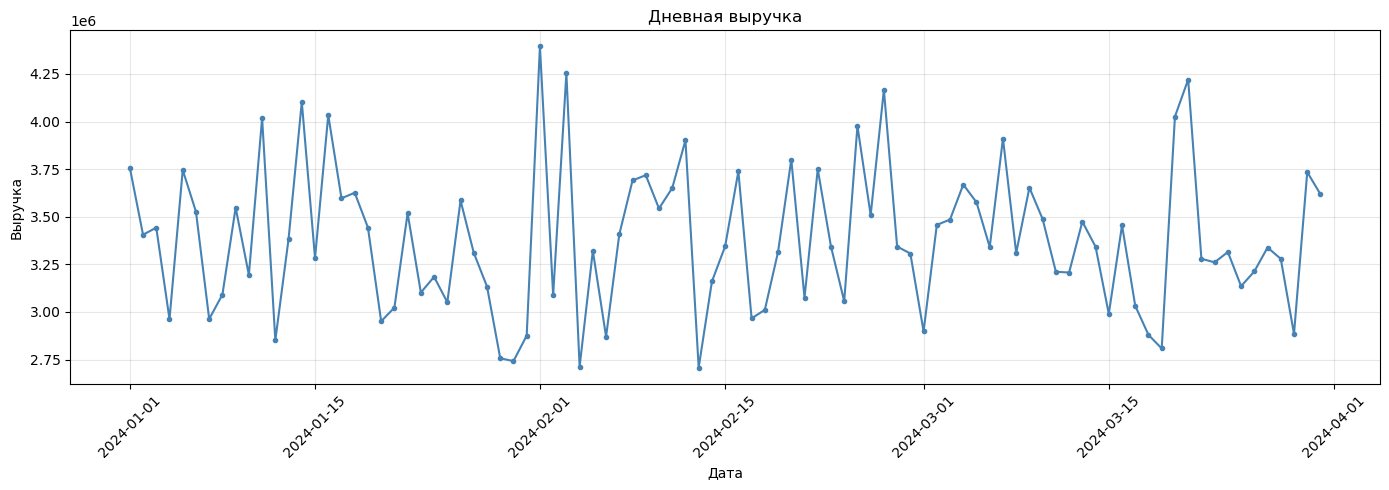

In [10]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(daily_full["order_date"], daily_full["revenue"],
        marker="o", markersize=3, linewidth=1.5, color="steelblue")
ax.set_title("Дневная выручка")
ax.set_xlabel("Дата")
ax.set_ylabel("Выручка")
ax.grid(True, alpha=0.3)
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [11]:
best_day = daily_full.loc[daily_full["revenue"].idxmax()]
print("День максимальной выручки:")
print(best_day.to_string())
print(f"\nДата: {best_day['order_date'].date()}, выручка: {best_day['revenue']:,.0f} руб.")

detail_max = orders_paid[orders_paid["order_datetime"].dt.date == best_day["order_date"].date()]
print(f"\nЗаказов в этот день: {len(detail_max)}")
print(detail_max[["order_id", "user_id", "product_id", "price", "quantity", "revenue"]]
      .sort_values("revenue", ascending=False).to_string(index=False))

День максимальной выручки:
order_date    2024-02-01 00:00:00
revenue                4394521.06

Дата: 2024-02-01, выручка: 4,394,521 руб.

Заказов в этот день: 164
 order_id  user_id  product_id    price  quantity  revenue
     6203     1022          20 18335.71         4 73342.84
     9320     1089          20 18296.09         4 73184.36
     5368     1054          18 17690.71         4 70762.84
     7190     1001           9 17664.34         4 70657.36
     6568     1046           3 17418.51         4 69674.04
     9032     1017          24 16937.13         4 67748.52
     6778     1014          13 16902.27         4 67609.08
     7318     1075           8 16589.64         4 66358.56
     8918     1062           9 16489.91         4 65959.64
     8440     1023           8 19737.15         3 59211.45
     8556     1023          16 14552.11         4 58208.44
     5061     1026          27 14373.07         4 57492.28
     8123     1052           6 18741.17         3 56223.51
     6409 

In [ ]:
worst_day = daily_full.loc[daily_full["revenue"].idxmin()]
print("День минимальной выручки:")
print(worst_day.to_string())
print(f"\nДата: {worst_day['order_date'].date()}, выручка: {worst_day['revenue']:,.0f} руб.")

# Сколько дней с нулевой выручкой
zero_days = daily_full[daily_full["revenue"] == 0]["order_date"].dt.date.tolist()
print(f"\nДней с нулевой выручкой: {len(zero_days)}")
print("Примеры:", zero_days[:5])

# Если нужен «минимум среди ненулевых»:
nonzero = daily_full[daily_full["revenue"] > 0]
worst_nonzero = nonzero.loc[nonzero["revenue"].idxmin()]
print(f"\nМинимум среди дней с продажами: "
      f"{worst_nonzero['order_date'].date()} — {worst_nonzero['revenue']:,.0f} руб.")